# Day 5 lecture: Simulation under uncertainty

<p class="lead">
Periods 1 to 6 of Day 5. How to turn a prediction into a decision when the future is uncertain: reading a regression as a manager and turning its error into a model input, building a spreadsheet model with separate inputs, calculations and outputs, contribution margin and break-even, sensitivity analysis and the tornado chart, one- and two-way What-If Data Tables, Scenario Manager and Goal Seek, the flaw of averages, Monte Carlo simulation with uniform, normal and triangular inputs, how many trials you need, risk measures such as the probability of a loss and the 5th percentile, correlated inputs, freezing a simulation, decision rules, and how to explain risk to executives. Period 6 ends with a bridge to Lab 5.
</p>

Every spreadsheet step is given twice: as a **numbered Excel click path with the formulas**, and as a **numpy mirror** with a fixed random seed, so that you can check one against the other. The case is a fictional drinks start-up, **Brightleaf**, launching a bottled cold-brew tea for one summer of festivals. All money is in **US dollars**. Lab 6, Lab 7 and Assignment 3 (tomorrow) use other businesses and other numbers; this lecture deliberately uses none of them, so that you practise each idea here and apply it yourself there.

- **Route B (Anaconda, offline):** open this notebook from the `DATA300_GAP` folder. It needs only numpy, pandas, matplotlib, scipy and statsmodels, and it downloads nothing.
- **Route A (Try JupyterLab):** upload this notebook and run `%pip install statsmodels scipy` in a first cell.
- **Excel:** any desktop Excel from 2016 on (Windows or Mac). Every function used here (`RAND`, `RANDBETWEEN`, `NORM.INV`, `PERCENTILE.INC`, `FORECAST.LINEAR`, `STEYX`) is built in. Data Tables, Scenario Manager and Goal Seek are under **Data → What-If Analysis** (on a Mac: **Data → What-If Analysis** as well, in the *Forecast* group on recent versions).

---

## What you will be able to do

1. Read a regression as a manager would, and turn its prediction and its error into an **uncertain input** for a spreadsheet model.
2. Build a model with separate **inputs, calculations and outputs**; compute **contribution margin**, **break-even** and **margin of safety**.
3. Run a **sensitivity analysis** and draw a **tornado chart** that ranks inputs by how much they move the result.
4. Build **one-way and two-way What-If Data Tables** in Excel, and know why their input cells must sit on the table's sheet.
5. Compare named cases with **Scenario Manager**, and solve backwards with **Goal Seek**.
6. Explain the **flaw of averages**: why a model run at average inputs can give the wrong average output.
7. Build a **Monte Carlo simulation** with `RAND`, `RANDBETWEEN` and `NORM.INV(RAND(), μ, σ)`, using uniform, normal and triangular inputs; **freeze** it with Paste Special → Values.
8. Decide **how many trials** are enough, and report the uncertainty of a simulated estimate.
9. Compute and explain **risk measures**: the probability of a loss, percentiles and a "1-in-20 bad year" figure (the 5th percentile, in the style of value at risk); read a **histogram** of outcomes.
10. Explain how **correlated inputs** change risk, apply **decision rules**, and **communicate risk** to executives in plain words.

This lecture fills six periods (P1 to P6). Each part is marked **core** (teach in class) or **extension** (faster students, a later study block, or self-study).

| Part | Topic | Path | Period |
|---|---|---|---|
| 1 | Reading a regression for a manager | Core | P1 |
| 2 | Anatomy of a spreadsheet model; the deterministic base case | Core | P2 |
| 3 | Sensitivity analysis and the tornado chart | Core | P2 |
| 4 | What-If Data Tables: one-way and two-way | Core | P3 |
| 5 | Scenario Manager and Goal Seek | Core | P3 |
| 6 | The flaw of averages | Core | P4 |
| 7 | Monte Carlo simulation: random inputs in Excel and numpy | Core | P4 |
| 8 | Freezing a simulation: Paste Special → Values | Core | P4 |
| 9 | How many trials? | Core | P4 |
| 10 | Risk measures and reading the histogram | Core | P5 |
| 11 | Correlated inputs | Core (concept), extension (Excel build) | P5 |
| 12 | Decision rules: how much to brew | Core | P5 |
| 13 | Communicating risk to executives | Core | P5 |
| 14 | Business case: Brightleaf's launch decision | Core (discussion) | P6 |
| 15 | Lab 5 bridge: train and test, residuals | Core | P6 |
| 16 | Practice, quiz and summary | Self-study | — |

> **Reading**
>
> Read Chapter 6 of the course reading packet for the inputs, calculations and output structure of a financial model and its colour convention, what a Data Table shows that a single formula cannot, Monte Carlo simulation with `RANDBETWEEN`-style sampling and its summary statistics (average, best case, worst case, probability of loss), freezing a result with Paste Special, and the risks a spreadsheet's formulas never capture. Its assigned readings (Wall Street Prep's financial-modelling guide and Workday's article on forecasting in Excel) also introduce `FORECAST.ETS`, which you meet tomorrow. Chapter 5 is the background for Part 1 and Part 15. This lecture adds the tornado chart, Scenario Manager and Goal Seek, the flaw of averages, the normal and triangular distributions, the number of trials, percentile-based risk measures, correlated inputs and decision rules.

### Setup

The first cell loads the libraries and sets colour-blind-safe colours. Every random number in this notebook comes from a numpy **generator with a fixed seed**, such as `np.random.default_rng(2026)`. A seed makes the "random" numbers repeat exactly each time the cell runs, which is what lets us talk about specific results. Excel's `RAND()` has no seed: your spreadsheet's numbers will differ from these, and from your neighbour's. They should be **close**, not identical (Part 9 explains how close).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import norm

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11})
# Okabe and Ito colour-blind-safe colours
BLUE, ORANGE, GREEN, PURPLE, SKY, GREY, YELLOW = "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#9A9A9A", "#E69F00"


def usd(x):
    """Format a dollar amount for printing, with a minus sign for losses."""
    return f"-${-x:,.0f}" if x < 0 else f"${x:,.0f}"

---

## Part 1: Reading a regression for a manager (core)

Yesterday you built regressions. Today a regression's output becomes the **input** to a decision model, so it pays to read it the way a manager must: what it predicts, how wrong it is likely to be, and where it stops applying.

**The case.** Brightleaf will sell a bottled cold-brew tea at summer festivals for one season, at **$4.00 a bottle**. It has booked **30 festival days**. How many bottles will it sell? The parent company has records of **24 earlier first-season launches** by its sister brands: how many festival days each booked, and how many bottles each sold in its first season.

> **Predict, then run.** Each extra festival day booked goes with how many extra bottles sold, roughly: 100, 1,000 or 10,000?

In [2]:
# 24 earlier first-season launches by sister brands (synthetic)
rng = np.random.default_rng(185)
days = rng.integers(10, 46, 24)
launches = pd.DataFrame({
    "festival_days": days,
    "bottles_sold": np.round(-1500 + 1380 * days + rng.normal(0, 8500, 24), -1),
})
print(launches.describe().round(0).loc[["count", "mean", "min", "max"]])

fit = smf.ols("bottles_sold ~ festival_days", data=launches).fit()
b0, b1 = fit.params["Intercept"], fit.params["festival_days"]
rmse_in = np.sqrt(fit.scale)            # standard error of the estimate (Excel: STEYX)
print(f"\nbottles_sold = {b0:,.0f} + {b1:,.0f} x festival_days")
print(f"R-squared: {fit.rsquared:.2f}   Standard error of the estimate: {rmse_in:,.0f} bottles")
lo, hi = fit.conf_int().loc["festival_days"]
print(f"95% confidence interval for the slope: {lo:,.0f} to {hi:,.0f} bottles per day")

       festival_days  bottles_sold
count           24.0          24.0
mean            25.0       32500.0
min             10.0        5180.0
max             45.0       61830.0

bottles_sold = -1,753 + 1,396 x festival_days
R-squared: 0.77   Standard error of the estimate: 8,668 bottles
95% confidence interval for the slope: 1,055 to 1,736 bottles per day


How a manager reads this output:

| Output | Sentence for a manager |
|---|---|
| Slope | "Among past launches, each extra festival day booked went with about 1,400 more bottles sold in the first season, **on average**." Not "booking a day *adds* 1,400 bottles": brands that expected to do well may have booked more days (Day 4, Part 12) |
| Intercept | The prediction for **zero** festival days. Nobody launches with zero days, so it has no business meaning; it only positions the line |
| R² | Festival days account for about three-quarters of the variation in first-season sales among these 24 launches. A quarter is something else: weather, flavour, location, luck |
| Standard error of the estimate | A typical miss for a single launch is **about 9,000 bottles**. This is the number a planner most needs, and it is often not on the slide |
| Range | The 24 launches booked between 10 and 45 days. Thirty days is inside that range, so we are **interpolating**, not extrapolating (Day 4, Part 11) |
| Sample size | 24 launches is a small sample: the slope's 95% interval is wide, and a different 24 launches would give a somewhat different line |

Now the step that links regression to today's topic. Brightleaf's planners need the **prediction for 30 days** and, just as importantly, **how far off it could be**.

Predicted first-season sales at 30 days: 40,119 bottles
Standard error for one new launch:       8,892 bottles
95% prediction interval:                 21,678 to 58,559 bottles


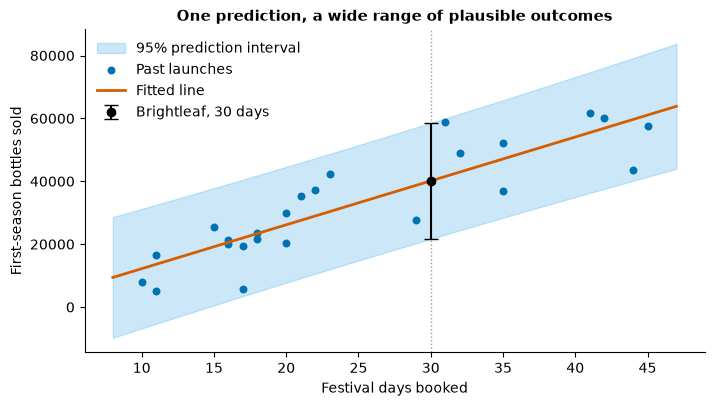

In [3]:
new = pd.DataFrame({"festival_days": [30]})
pred = fit.get_prediction(new).summary_frame(alpha=0.05)
point = pred["mean"].iloc[0]
se_pred = np.sqrt(pred["mean_se"].iloc[0] ** 2 + fit.scale)   # error of a single new launch
print(f"Predicted first-season sales at 30 days: {point:,.0f} bottles")
print(f"Standard error for one new launch:       {se_pred:,.0f} bottles")
print(f"95% prediction interval:                 {pred['obs_ci_lower'].iloc[0]:,.0f} "
      f"to {pred['obs_ci_upper'].iloc[0]:,.0f} bottles")

xs = np.linspace(8, 47, 100)
band = fit.get_prediction(pd.DataFrame({"festival_days": xs})).summary_frame(alpha=0.05)
fig, ax = plt.subplots()
ax.fill_between(xs, band["obs_ci_lower"], band["obs_ci_upper"], color=SKY, alpha=0.3,
                label="95% prediction interval")
ax.scatter(launches["festival_days"], launches["bottles_sold"], color=BLUE, s=22, label="Past launches")
ax.plot(xs, band["mean"], color=ORANGE, lw=2, label="Fitted line")
ax.axvline(30, color=GREY, ls=":", lw=1)
ax.errorbar(30, point, yerr=[[point - pred["obs_ci_lower"].iloc[0]], [pred["obs_ci_upper"].iloc[0] - point]],
            fmt="o", color="black", capsize=5, label="Brightleaf, 30 days")
ax.set_xlabel("Festival days booked")
ax.set_ylabel("First-season bottles sold")
ax.set_title("One prediction, a wide range of plausible outcomes")
ax.legend(frameon=False, loc="upper left")
plt.show()

The prediction is about **40,000 bottles**, but a single new launch could plausibly land anywhere from about **22,000 to 59,000**. A regression's prediction is not a number; it is the **centre of a distribution**. For the rest of the day, Brightleaf's planners treat demand as uncertain with:

> **mean demand = 40,000 bottles** and **standard deviation = 9,000 bottles** (both rounded from the output above).

That pair of numbers is exactly what `NORM.INV(RAND(), 40000, 9000)` needs in Part 7. This is the bridge from **predictive** analytics (Day 4) to **prescriptive** analytics (today): the prediction says what is likely; the simulation says what to do about it.

### Excel steps: the same regression in a spreadsheet

Put the 24 launches in a sheet named `Launches`, festival days in `A2:A25` and bottles sold in `B2:B25`.

1. **Slope:** in `D2` type `=SLOPE(B2:B25, A2:A25)`. **Intercept:** in `D3` type `=INTERCEPT(B2:B25, A2:A25)`. **R²:** in `D4` type `=RSQ(B2:B25, A2:A25)`.
2. **Prediction at 30 days:** in `D5` type `=FORECAST.LINEAR(30, B2:B25, A2:A25)`. (Older Excel: `=FORECAST(...)`, same arguments.)
3. **Standard error of the estimate:** in `D6` type `=STEYX(B2:B25, A2:A25)`.
4. **Standard error for one new launch** (slightly larger than `STEYX`, because the line itself is uncertain): in `D7` type
   `=D6*SQRT(1 + 1/COUNT(A2:A25) + (30-AVERAGE(A2:A25))^2/DEVSQ(A2:A25))`.
5. **95% prediction interval:** in `D8` type `=D5 - T.INV.2T(0.05, COUNT(A2:A25)-2)*D7` and in `D9` type `=D5 + T.INV.2T(0.05, COUNT(A2:A25)-2)*D7`.
6. **Full regression table (optional):** **File → Options → Add-ins → Manage: Excel Add-ins → Go… → tick Analysis ToolPak → OK** (Mac: **Tools → Excel Add-ins… → Analysis ToolPak**). Then **Data → Data Analysis → Regression → OK**; *Input Y Range* `B1:B25`, *Input X Range* `A1:A25`, tick *Labels* → **OK**. The *Standard Error* in the *Regression Statistics* block is the same number as `STEYX`.

The numpy mirror below recomputes steps 1–5 from the formulas, so you can see there is nothing hidden in Excel's functions.

In [4]:
x, y = launches["festival_days"].to_numpy(), launches["bottles_sold"].to_numpy()
n = len(x)
slope = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)    # SLOPE
intercept = y.mean() - slope * x.mean()                                           # INTERCEPT
steyx = np.sqrt(np.sum((y - (intercept + slope * x)) ** 2) / (n - 2))             # STEYX
forecast = intercept + slope * 30                                                 # FORECAST.LINEAR
se_new = steyx * np.sqrt(1 + 1 / n + (30 - x.mean()) ** 2 / np.sum((x - x.mean()) ** 2))
print(f"SLOPE {slope:,.1f}   INTERCEPT {intercept:,.0f}   STEYX {steyx:,.0f}")
print(f"FORECAST.LINEAR(30) {forecast:,.0f}   SE for a new launch {se_new:,.0f}")
print("Matches statsmodels:", np.isclose(forecast, point) and np.isclose(se_new, se_pred))

SLOPE 1,395.7   INTERCEPT -1,753   STEYX 8,668
FORECAST.LINEAR(30) 40,119   SE for a new launch 8,892
Matches statsmodels: True


> **Misconception:** "R² is 0.77, so the prediction is 77% accurate." R² compares the line with simply predicting the average launch. It says nothing directly about how far off **one** prediction may be. For planning, the standard error (in bottles) is the number that matters.

> **Check your understanding.** A colleague plans the season around "40,000 bottles" and nothing else. Using the prediction interval, give one way the plan could go badly wrong in each direction.

### Five questions a manager should ask of any regression

1. **What is it for?** Predicting a number (judge the error on new cases) or explaining a lever (judge the coefficients and confounding)?
2. **How big is a typical miss, in the units I care about?** Ask for RMSE or the standard error, not only R².
3. **Was it tested on data it had not seen?** (Part 15; Day 4, Part 5.)
4. **Is my case inside the range of the data?**
5. **Would acting on the lever really change the outcome?** A coefficient is a comparison, not a promise.

---

## Part 2: Anatomy of a spreadsheet model; the deterministic base case (core)

A **financial model** turns assumptions into a result. A good one has three visibly separate layers:

| Layer | What it holds | Convention |
|---|---|---|
| **Inputs** (assumptions) | Numbers nobody can calculate from anything else: price, unit cost, demand, fees | Typed in once, coloured **blue** |
| **Calculations** | Formulas that combine inputs | **Black**; never type a number into a formula |
| **Outputs** | The few numbers a decision-maker reads: profit, break-even | Clearly labelled, often boxed |

Why it matters: when the price changes, you change **one blue cell** and every result updates. A number typed inside a formula (`=40000*4-60000`) is invisible, cannot be varied by a Data Table, and is the most common cause of wrong spreadsheets.

### Brightleaf's base case

The **deterministic base case** uses one value for every input, usually the planners' best guess. "Deterministic" means no randomness: the same inputs always give the same output.

| Input | Value | Notes |
|---|---|---|
| Price per bottle | $4.00 | Brightleaf's decision |
| Variable cost per bottle | $1.70 | Tea, bottle, label, cold storage; the most likely value |
| Festival days | 30 | Booked |
| Stall fee per day | $1,200 | Charged by the festivals |
| Equipment and marketing | $24,000 | For the season |
| Demand | 40,000 bottles | From Part 1 |

Three ideas carry most of the analysis:

- **Contribution margin** per bottle = price − variable cost = $4.00 − $1.70 = **$2.30**. Each bottle sold "contributes" $2.30 towards the fixed costs, and then to profit.
- **Fixed costs** = 30 × $1,200 + $24,000 = **$60,000**. They are paid whether Brightleaf sells one bottle or 60,000.
- **Break-even demand** = fixed costs ÷ contribution margin = $60,000 ÷ $2.30 ≈ **26,087 bottles**: the sales at which profit is exactly zero.
- **Margin of safety** = (expected demand − break-even) ÷ expected demand: how far demand can fall short of the plan before the season loses money.

> **Predict, then run.** At 40,000 bottles, will the season's profit be nearer $10,000, $30,000 or $90,000? And how far can demand fall below 40,000 before Brightleaf loses money: about 10%, 35% or 60%?

In [5]:
inputs = {"price": 4.00, "unit_cost": 1.70, "days": 30, "stall_fee": 1200,
          "equipment_marketing": 24000, "demand": 40000}


def model(price, unit_cost, days, stall_fee, equipment_marketing, demand):
    """Brightleaf's season, brewing exactly what is sold (the simple model)."""
    margin = price - unit_cost                              # contribution margin per bottle
    fixed = days * stall_fee + equipment_marketing          # fixed costs
    revenue = price * demand
    variable = unit_cost * demand
    profit = revenue - variable - fixed
    break_even = fixed / margin
    return {"contribution_margin": margin, "fixed_costs": fixed, "revenue": revenue,
            "variable_costs": variable, "profit": profit, "break_even_demand": break_even,
            "margin_of_safety": (demand - break_even) / demand}


base = model(**inputs)
for k, v in base.items():
    print(f"{k:>20}: {v:>12,.2f}" if k in ("contribution_margin", "margin_of_safety") else f"{k:>20}: {v:>12,.0f}")

 contribution_margin:         2.30
         fixed_costs:       60,000
             revenue:      160,000
      variable_costs:       68,000
              profit:       32,000
   break_even_demand:       26,087
    margin_of_safety:         0.35


The base case says **$32,000 profit**, with a break-even at about **26,100 bottles** and a margin of safety of about **35%**: demand can fall roughly a third below plan before the season makes a loss. Part 1 showed that demand could easily land below 26,000, which is the first hint that the base case alone is not enough.

### Excel steps: build the model sheet

Name the sheet `Model`. Type the labels in column A, the inputs in column B and the calculations in column E, exactly as below. Colour the inputs in `B4:B9` blue (**Home → Font Color**).

1. `A3` *Inputs*. `A4` *Price per bottle*, `B4` `4`. `A5` *Variable cost per bottle*, `B5` `1.7`. `A6` *Festival days*, `B6` `30`. `A7` *Stall fee per day*, `B7` `1200`. `A8` *Equipment and marketing*, `B8` `24000`. `A9` *Demand (bottles)*, `B9` `40000`.
2. `D3` *Calculations and outputs*. `D4` *Contribution margin*, `E4` `=B4-B5`.
3. `D5` *Fixed costs*, `E5` `=B6*B7+B8`.
4. `D6` *Revenue*, `E6` `=B4*B9`. `D7` *Variable costs*, `E7` `=B5*B9`.
5. `D8` *Profit*, `E8` `=E6-E7-E5`. Put a border round `E8` (**Home → Borders → Thick Outside Borders**): it is the output.
6. `D9` *Break-even demand*, `E9` `=E5/E4`. `D10` *Margin of safety*, `E10` `=(B9-E9)/B9`, formatted as a percentage (**Home → %**).
7. Format money cells as currency (**Home → Number Format → Currency**).
8. **Check:** `E8` shows $32,000 and `E9` about 26,087. Then change `B4` to `4.5` and watch `E8`, `E9` and `E10` update; change it back.

> **Misconception:** "The base case is the most likely outcome." It is the outcome at the most likely value of **each input**. With several uncertain inputs, the chance that every one lands on its single most likely value at once is small. Part 6 shows that the base case can even be a poor guide to the **average** outcome.

> **Check your understanding.** The festival organisers offer a package: no stall fee, but they keep $0.40 of every bottle sold. Which cells change, and does the break-even demand rise or fall?

---

## Part 3: Sensitivity analysis and the tornado chart (core)

A **sensitivity analysis** asks: if one input is wrong, how much does the output move? The simplest version is **one at a time**: set each input to a plausible **low** and **high** value while holding all others at the base case, and record the profit each time.

Brightleaf's planners agreed these ranges. For demand they used the 10th and 90th percentiles of the Part 1 distribution, 40,000 ± 1.28 × 9,000.

| Input | Low | Base | High |
|---|---|---|---|
| Demand (bottles) | 28,466 | 40,000 | 51,534 |
| Price | $3.50 | $4.00 | $4.50 |
| Variable cost | $1.50 | $1.70 | $2.20 |
| Stall fee per day | $1,000 | $1,200 | $1,500 |
| Equipment and marketing | $20,000 | $24,000 | $30,000 |

> **Predict, then run.** Rank the five inputs from the one that moves profit most to the one that moves it least.

              input  profit_at_low  profit_at_high   swing
             demand         5471.0         58529.0 53058.0
              price        12000.0         52000.0 40000.0
          unit_cost        40000.0         12000.0 28000.0
          stall_fee        38000.0         23000.0 15000.0
equipment_marketing        36000.0         26000.0 10000.0


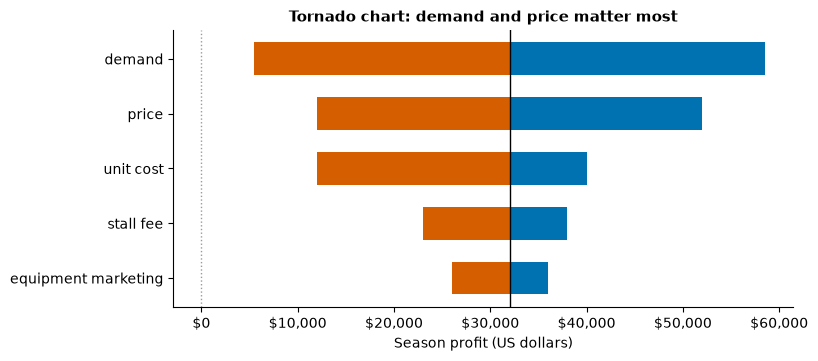

In [6]:
ranges = {
    "demand": (40000 - 1.2816 * 9000, 40000 + 1.2816 * 9000),
    "price": (3.50, 4.50),
    "unit_cost": (1.50, 2.20),
    "stall_fee": (1000, 1500),
    "equipment_marketing": (20000, 30000),
}
rows = []
for name, (low, high) in ranges.items():
    p_low = model(**{**inputs, name: low})["profit"]
    p_high = model(**{**inputs, name: high})["profit"]
    rows.append({"input": name, "profit_at_low": p_low, "profit_at_high": p_high,
                 "swing": abs(p_high - p_low)})
tornado = pd.DataFrame(rows).sort_values("swing", ascending=False).reset_index(drop=True)
print(tornado.round(0).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.6))
base_profit = base["profit"]
order = tornado.iloc[::-1]
for i, r in enumerate(order.itertuples()):
    left, right = sorted([r.profit_at_low, r.profit_at_high])
    ax.barh(i, base_profit - left, left=left, color=ORANGE, height=0.6)
    ax.barh(i, right - base_profit, left=base_profit, color=BLUE, height=0.6)
ax.axvline(base_profit, color="black", lw=1)
ax.axvline(0, color=GREY, ls=":", lw=1)
ax.set_yticks(range(len(order)), order["input"].str.replace("_", " "))
ax.set_xlabel("Season profit (US dollars)")
ax.set_title("Tornado chart: demand and price matter most")
ax.xaxis.set_major_formatter(lambda v, _: usd(v))
plt.show()

Read a tornado chart from the top: the **widest bar** is the input whose uncertainty matters most. Here demand swings profit by about $53,000, more than any other input, and price is second. Two lessons for the business:

- **Spend effort where the bar is wide.** Better demand information (a pilot, pre-orders) is worth more than haggling over the equipment budget.
- **Asymmetric bars carry information.** The variable-cost bar is longer on the bad side, because the planners think a cost rise to $2.20 is more plausible than a fall to $1.50. Part 6 shows why that skew matters.

Price is different from the others: it is Brightleaf's **decision**, not an uncertainty. A tornado chart can include decisions, but label them, because the response is different (choose it, rather than plan around it).

### Excel steps: a tornado chart

1. On the `Model` sheet, set up a small table in `G3:J8`: headers `G3` *Input*, `H3` *Profit at low*, `I3` *Profit at high*, `J3` *Swing*; input names in `G4:G8`.
2. Fill `H4:I8` by changing each input in column B to its low value, copying the profit from `E8`, then its high value, then putting the base value back. (Faster: use one-way Data Tables from Part 4, or paste the values with **Paste Special → Values**.) Never leave an input at a test value.
3. In `J4` type `=ABS(I4-H4)` and fill down to `J8`.
4. Select `G3:J8` → **Data → Sort** → *Sort by* **Swing**, *Order* **Largest to Smallest** → OK.
5. Add two helper columns: `K4` `=MIN(H4,I4)-$E$8` (the bar to the left) and `L4` `=MAX(H4,I4)-$E$8` (the bar to the right); fill down.
6. Select `G3:G8`, then hold **Ctrl** (Mac: **Cmd**) and select `K3:L8` → **Insert → Charts → Bar → Clustered Bar**.
7. Right-click a bar → **Format Data Series** → *Series Overlap* **100%**, *Gap Width* **50%**.
8. Right-click the vertical axis → **Format Axis** → tick **Categories in reverse order**, and set *Label Position* to **Low** so the labels sit at the left edge. The widest bar is now at the top. The horizontal axis shows the change from the base profit.

> **Misconception:** "One-at-a-time sensitivity shows the worst case." It moves **one** input at a time. In a bad season, demand may be low **and** the cost high together; that combination is not on the chart. Data Tables (two inputs at once) and simulation (all inputs at once) fill that gap.

---

## Part 4: What-If Data Tables: one-way and two-way (core)

A **Data Table** recalculates one formula for a whole list of input values, and lays the results out in a grid. It answers "what if demand is 20,000? 25,000? … 60,000?" in one step, without touching the model.

- A **one-way** table varies **one** input and can show several outputs.
- A **two-way** table varies **two** inputs and shows **one** output for every combination.

> **Predict, then run.** In the two-way table below, at a price of **$3.50**, at roughly what demand does profit cross zero? (Hint: contribution margin and fixed costs.)

In [7]:
# One-way: profit and revenue for demand from 20,000 to 60,000 bottles
demand_values = np.arange(20000, 60001, 5000)
one_way = pd.DataFrame({
    "demand": demand_values,
    "revenue": [model(**{**inputs, "demand": d})["revenue"] for d in demand_values],
    "profit": [model(**{**inputs, "demand": d})["profit"] for d in demand_values],
})
print("One-way Data Table (demand)")
print(one_way.to_string(index=False, formatters={"revenue": usd, "profit": usd}))

# Two-way: profit for each price (columns) and demand (rows), using numpy broadcasting
prices = np.array([3.00, 3.50, 4.00, 4.50, 5.00])
D, P = np.meshgrid(demand_values, prices, indexing="ij")
fixed = inputs["days"] * inputs["stall_fee"] + inputs["equipment_marketing"]
profit_grid = (P - inputs["unit_cost"]) * D - fixed
two_way = pd.DataFrame(profit_grid, index=demand_values, columns=[f"${p:.2f}" for p in prices])
two_way.index.name = "demand"
print("\nTwo-way Data Table: profit by demand (rows) and price (columns)")
print(two_way.map(lambda v: f"{v:>10,.0f}").to_string())

One-way Data Table (demand)
 demand  revenue   profit
  20000  $80,000 -$14,000
  25000 $100,000  -$2,500
  30000 $120,000   $9,000
  35000 $140,000  $20,500
  40000 $160,000  $32,000
  45000 $180,000  $43,500
  50000 $200,000  $55,000
  55000 $220,000  $66,500
  60000 $240,000  $78,000

Two-way Data Table: profit by demand (rows) and price (columns)
             $3.00       $3.50       $4.00       $4.50       $5.00
demand                                                            
20000      -34,000     -24,000     -14,000      -4,000       6,000
25000      -27,500     -15,000      -2,500      10,000      22,500
30000      -21,000      -6,000       9,000      24,000      39,000
35000      -14,500       3,000      20,500      38,000      55,500
40000       -8,000      12,000      32,000      52,000      72,000
45000       -1,500      21,000      43,500      66,000      88,500
50000        5,000      30,000      55,000      80,000     105,000
55000       11,500      39,000      66,500  

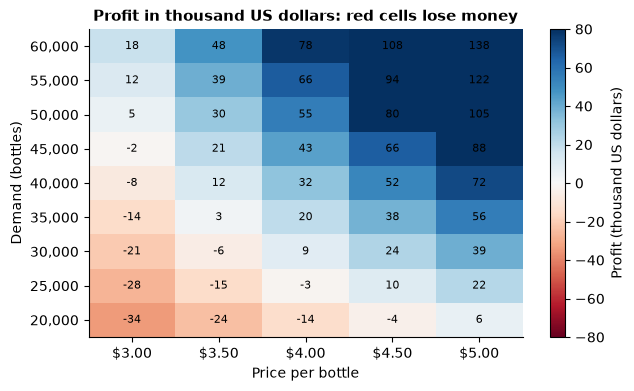

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(profit_grid / 1000, cmap="RdBu", vmin=-80, vmax=80, aspect="auto", origin="lower")
ax.set_xticks(range(len(prices)), [f"${p:.2f}" for p in prices])
ax.set_yticks(range(len(demand_values)), [f"{d:,}" for d in demand_values])
for i in range(len(demand_values)):
    for j in range(len(prices)):
        ax.text(j, i, f"{profit_grid[i, j] / 1000:,.0f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("Price per bottle")
ax.set_ylabel("Demand (bottles)")
ax.set_title("Profit in thousand US dollars: red cells lose money")
fig.colorbar(im, ax=ax, label="Profit (thousand US dollars)")
plt.show()

The table shows the **boundary** between profit and loss, which no single cell can. At $3.50, the contribution margin is $1.80 and the break-even is $60,000 ÷ $1.80 ≈ 33,300 bottles, so the zero line falls between the 30,000 and 35,000 rows. At $5.00, Brightleaf breaks even below 20,000.

A Data Table has a blind spot: it treats price and demand as **independent**. In reality a higher price usually means fewer bottles sold. The $5.00 column is not wrong arithmetic, but it answers "what if we charged $5.00 **and still** sold 40,000?", which may be fantasy. Part 11 returns to inputs that move together.

### Excel steps: one-way Data Table (demand)

The **input cell must be on the same sheet as the Data Table.** If you build the table on another sheet and click an input cell on `Model`, Excel refuses with *"Input cell reference is not valid."* So build the tables on the `Model` sheet (or move the inputs to the table's sheet).

1. On `Model`, type the demand values down a column: `G13` `20000`, `G14` `25000`, … `G21` `60000`. (Type the first two, select both, and drag the fill handle down.)
2. In the row **above the first value and one column to the right**, link the outputs: `H12` `=E6` (revenue) and `I12` `=E8` (profit). Leave `G12` empty.
3. Select the whole block **`G12:I21`**, including the empty corner, the formula row and the values.
4. **Data → What-If Analysis → Data Table…**
5. Leave *Row input cell* empty. In *Column input cell*, click **`B9`** (demand), because the demand values run down a **column**. → **OK**.
6. Excel fills `H13:I21` with `{=TABLE(,B9)}`. You cannot edit one cell of it; to change it, select the whole result range `H13:I21` and press **Delete**, then rebuild.
7. Format the results as currency. Hide the link row if you like (custom number format `;;;` on `H12:I12`).

### Excel steps: two-way Data Table (price × demand)

1. In `K13:K21` type the demand values again (20000 … 60000).
2. In `L12:P12` type the prices `3`, `3.5`, `4`, `4.5`, `5`.
3. In the **corner cell `K12`** type `=E8`. A two-way table has exactly **one** output, and it lives in the corner.
4. Select **`K12:P21`**.
5. **Data → What-If Analysis → Data Table…** → *Row input cell* **`B4`** (price, because prices run along the **row**) → *Column input cell* **`B9`** (demand) → **OK**.
6. Colour the result: select `L13:P21` → **Home → Conditional Formatting → Color Scales → Red-White-Blue** (or **Highlight Cells Rules → Less Than… 0** in red).

**Check:** the cell for demand 40,000 at price $4.00 shows **$32,000**, the base case.

| Data Table trouble | Cause | Fix |
|---|---|---|
| *Input cell reference is not valid* | The input cell is on a different sheet from the table | Build the table on the inputs' sheet |
| Every result cell shows the same number | Row and column input cells swapped, or the wrong cell chosen | Delete the results and rebuild; prices along the top → **row** input |
| The table does not update when inputs change | **Formulas → Calculation Options** is set to *Automatic Except for Data Tables* | Press **F9**, or choose *Automatic* |
| *Cannot change part of a data table* | You tried to edit one result cell | Select the whole result range and delete it |
| Results ignore the corner formula | The corner cell holds a number, not a formula linked to the output | Type `=E8` in the corner |

> **Misconception:** "The Data Table is a simulation." It is a **systematic sweep**: every listed value counts once, however unlikely. A value at the edge of the grid looks as important as the centre. A simulation (Part 7) weights values by how likely they are.

---

## Part 5: Scenario Manager and Goal Seek (core)

### Scenarios: coherent stories, not single inputs

A **scenario** changes **several inputs together** to tell a consistent story. Brightleaf's planners wrote four:

| Scenario | Demand | Variable cost | Stall fee | Story |
|---|---|---|---|---|
| Base | 40,000 | $1.70 | $1,200 | The plan |
| Wet summer | 28,000 | $1.70 | $1,200 | Rain keeps crowds small |
| Hot summer | 52,000 | $1.90 | $1,200 | Big crowds; extra ice and cold storage |
| Supplier squeeze | 40,000 | $2.10 | $1,300 | Tea prices rise; festivals raise fees |

> **Predict, then run.** Which scenario is worst for profit? Is the "Hot summer" better or worse than the base case, given that its cost is higher?

In [9]:
scenarios = {
    "Base": {},
    "Wet summer": {"demand": 28000},
    "Hot summer": {"demand": 52000, "unit_cost": 1.90},
    "Supplier squeeze": {"unit_cost": 2.10, "stall_fee": 1300},
}
summary = pd.DataFrame({name: model(**{**inputs, **change}) for name, change in scenarios.items()}).T
summary = summary[["revenue", "variable_costs", "fixed_costs", "profit", "break_even_demand"]]
print(summary.map(lambda v: f"{v:>10,.0f}").to_string())

                     revenue variable_costs fixed_costs      profit break_even_demand
Base                 160,000         68,000      60,000      32,000            26,087
Wet summer           112,000         47,600      60,000       4,400            26,087
Hot summer           208,000         98,800      60,000      49,200            28,571
Supplier squeeze     160,000         84,000      63,000      13,000            33,158


Scenarios are good for **communication** ("in a wet summer, profit falls to about $4,000; under a supplier squeeze, to about $13,000") and for checking that the model behaves sensibly in each story. They are **not probabilities**: four scenarios do not mean each has a 25% chance, and "Base" is not "the" outcome. They also leave out every combination nobody wrote down.

### Excel steps: Scenario Manager

1. First give the input cells names, so the report is readable: click `B5` → type `UnitCost` in the **Name Box** (left of the formula bar) → **Enter**. Do the same for `B7` (`StallFee`), `B9` (`Demand`) and `E8` (`Profit`).
2. **Data → What-If Analysis → Scenario Manager… → Add…**
3. *Scenario name* **Base**; *Changing cells* `B5,B7,B9` (type them with commas, or Ctrl-click / Cmd-click) → **OK** → keep the current values → **OK**.
4. **Add…** again: **Wet summer**, same changing cells → **OK** → enter `1.7`, `1200`, `28000` → **OK**. Repeat for **Hot summer** (`1.9`, `1200`, `52000`) and **Supplier squeeze** (`2.1`, `1300`, `40000`).
5. To view one scenario on the model, select it and click **Show**. To put the base back, show **Base**.
6. **Summary… →** *Report type* **Scenario summary**, *Result cells* `E8,E9` → **OK**. Excel adds a new sheet, *Scenario Summary*, with one column per scenario. It is a static snapshot: re-run the summary if the model changes.

### Goal Seek: solving backwards

**Goal Seek** answers "what input value gives the output I want?" by trial and error on **one** input cell.

- **Break-even demand:** set profit to 0 by changing demand. (We know the answer from the formula, so this is a good test of the tool.)
- **Price for a target:** at a cautious demand of 35,000 bottles, what price gives a profit of $40,000?

> **Predict, then run.** Is the price needed for $40,000 at 35,000 bottles above or below $4.50?

In [10]:
def goal_seek(f, target, lo, hi, tol=1e-6):
    """Find x in [lo, hi] with f(x) = target by bisection (Goal Seek does a similar search)."""
    for _ in range(200):
        mid = (lo + hi) / 2
        if (f(lo) - target) * (f(mid) - target) <= 0:
            hi = mid
        else:
            lo = mid
        if hi - lo < tol:
            break
    return (lo + hi) / 2


be = goal_seek(lambda d: model(**{**inputs, "demand": d})["profit"], 0, 1, 100000)
p_needed = goal_seek(lambda p: model(**{**inputs, "demand": 35000, "price": p})["profit"], 40000, 1, 10)
print(f"Goal Seek, profit = 0 by changing demand:          {be:,.2f} bottles")
print(f"Formula check, fixed / margin:                     {base['break_even_demand']:,.2f} bottles")
print(f"Goal Seek, profit = $40,000 at 35,000 by changing price: ${p_needed:.3f}")

Goal Seek, profit = 0 by changing demand:          26,086.96 bottles
Formula check, fixed / margin:                     26,086.96 bottles
Goal Seek, profit = $40,000 at 35,000 by changing price: $4.557


### Excel steps: Goal Seek

1. **Data → What-If Analysis → Goal Seek…**
2. *Set cell* **`E8`** (profit; it must contain a formula) · *To value* **`0`** · *By changing cell* **`B9`** (demand; it must be a typed input) → **OK**.
3. Excel reports *Goal Seeking with Cell E8 found a solution* and shows about **26,087** in `B9`. Click **Cancel** to put the original 40,000 back, or **OK** to keep the new value. **Goal Seek overwrites your input**, so choose Cancel unless you mean to keep it.
4. For the price question: set `B9` to `35000`, then *Set cell* `E8`, *To value* `40000`, *By changing cell* `B4` → **OK** → read the price → **Cancel**. Put `B9` back to `40000`.

Goal Seek changes only **one** input and finds only **one** answer. For several inputs, or a target such as "the largest profit", Excel's **Solver** add-in does the job (it is an extension beyond this course). Never point Goal Seek at a cell that contains `RAND()`: the target moves every time Excel recalculates.

> **Check your understanding.** The Goal Seek answer for break-even is 26,086.96 bottles. How would you report it to the board, and why not to two decimal places?

---

## Part 6: The flaw of averages (core)

So far, profit has been a **straight-line** function of each input. Real businesses have kinks. Brightleaf has one: cold brew must be **brewed and bottled before the season**, because the festivals have no kitchen. Brightleaf plans to brew **45,000 bottles**, a little above expected demand. Then:

- bottles sold = the **smaller** of demand and bottles brewed: `MIN(demand, 45000)`;
- the variable cost is paid on every bottle **brewed**, sold or not;
- unsold bottles are sold to a discount retailer at a **salvage price**, about $0.50.

There is also a second subtlety. The planners' cost of $1.70 is the **most likely** value, but they think costs could rise to $2.20 more easily than fall to $1.50. The **average** of such a skewed range is higher than its most likely value (for a triangular range, (1.50 + 1.70 + 2.20) ÷ 3 = **$1.80**).

The **flaw of averages** (Sam Savage's name for it) is the belief that plugging average inputs into a model gives the average output. It is true only for straight-line models. With a kink like `MIN`, it is false.

**A pencil example.** Suppose demand is equally likely to be 31,000, 40,000 or 49,000 (average 40,000), the cost is $1.80, and Brightleaf brews 45,000.

| Demand | Sold | Revenue + salvage | Cost of 45,000 brewed | Fixed | Profit |
|---|---|---|---|---|---|
| 31,000 | 31,000 | $124,000 + $7,000 | $81,000 | $60,000 | −$10,000 |
| 40,000 | 40,000 | $160,000 + $2,500 | $81,000 | $60,000 | $21,500 |
| 49,000 | **45,000** | $180,000 + $0 | $81,000 | $60,000 | $39,000 |
| **Average** | | | | | **$16,833** |

The profit **at** average demand is $21,500, but the **average** profit is $16,833. In good seasons the extra demand is lost (Brightleaf runs out), while in bad seasons every unsold bottle still cost money. The downside counts in full; the upside is capped.

> **Predict, then run.** The code computes Brightleaf's profit three ways: at the most likely inputs, at the average inputs, and as the average of 10,000 simulated seasons. Put the three in order from largest to smallest.

In [11]:
PRICE, Q, FIXED = 4.00, 45000, 60000


def brew_profit(demand, unit_cost, salvage, brewed=Q, price=PRICE, fixed=FIXED):
    """Season profit when `brewed` bottles are made in advance (works on arrays too)."""
    sold = np.minimum(demand, brewed)
    return price * sold + salvage * (brewed - sold) - unit_cost * brewed - fixed


at_most_likely = brew_profit(40000, 1.70, 0.50)
at_average = brew_profit(40000, (1.50 + 1.70 + 2.20) / 3, 0.50)

rng = np.random.default_rng(2026)
n = 10_000
sim_demand = np.maximum(0, np.round(rng.normal(40000, 9000, n)))
sim_cost = rng.triangular(1.50, 1.70, 2.20, n)
sim_salvage = rng.uniform(0.30, 0.70, n)
sim_profit = brew_profit(sim_demand, sim_cost, sim_salvage)

print(f"Profit at the most likely inputs (base case):  {usd(at_most_likely)}")
print(f"Profit at the average inputs:                  {usd(at_average)}")
print(f"Average profit over {n:,} simulated seasons:    {usd(sim_profit.mean())}")

Profit at the most likely inputs (base case):  $26,000
Profit at the average inputs:                  $21,500
Average profit over 10,000 simulated seasons:    $15,771


All three numbers describe "the same" plan, and they differ by about $10,000:

1. **Base case to average inputs** (about $26,000 to $21,500): the most likely cost is not the average cost when the range is skewed.
2. **Average inputs to average outcome** (about $21,500 to about $16,000): the `MIN` kink. Running out in good seasons costs more than average demand reveals.

A plan built on the base case overstates the expected profit by more than half. Neither error is visible in a single-number spreadsheet, however carefully built. Kinks like this are everywhere: capacity limits, stock-outs, minimum orders, contract caps, tax thresholds, overtime.

> **Misconception:** "If I use the right averages, I get the right answer." Only if the model is a straight line in every uncertain input. The simple model of Part 2 is (and there the average of simulated profits does equal profit at average inputs). The brew-in-advance model is not.

### Excel steps: add the brew-in-advance model

On the `Model` sheet, below the simple model:

1. `A10` *Bottles brewed in advance*, `B10` `45000`. `A11` *Salvage price per unsold bottle*, `B11` `0.5`. (Blue: these are inputs.)
2. `D12` *Bottles sold*, `E12` `=MIN(B9,B10)`.
3. `D13` *Unsold bottles*, `E13` `=B10-E12`.
4. `D14` *Profit, brewing in advance*, `E14` `=B4*E12 + B11*E13 - B5*B10 - E5`.
5. **Check:** `E14` shows **$26,000** at the base inputs. Now change `B5` to `1.8` and check **$21,500**; put `B5` back to `1.7`.

---

## Part 7: Monte Carlo simulation: random inputs in Excel and numpy (core)

A **Monte Carlo simulation** replaces each uncertain input with a **random draw** from a distribution, computes the output, and repeats this thousands of times. Each row is one possible season. The collection of results is a **distribution of outcomes**, from which we read averages, ranges and the chance of a loss.

### Choosing a distribution for each input

| Distribution | Shape | Use it when | Excel | numpy |
|---|---|---|---|---|
| **Uniform** (continuous) | Flat between a low and a high | You know only a range, nothing about where in it | `=low+(high-low)*RAND()` | `rng.uniform(low, high)` |
| **Uniform** (whole numbers) | Flat, integers only | Counts with a known range | `=RANDBETWEEN(low, high)` (both ends included) | `rng.integers(low, high + 1)` |
| **Normal** | Bell curve: mean μ, standard deviation σ | Symmetric uncertainty, e.g. a regression prediction (Part 1) | `=NORM.INV(RAND(), μ, σ)` | `rng.normal(μ, σ)` |
| **Triangular** | Rises from a minimum to a most likely value, falls to a maximum | Expert judgement: "at least, most likely, at most" | formula below | `rng.triangular(min, mode, max)` |

**Why `NORM.INV(RAND(), μ, σ)` works.** `RAND()` gives a number between 0 and 1, every value equally likely. `NORM.INV(p, μ, σ)` returns the value that a normal variable stays below with probability *p*. Feeding it a uniform random *p* turns flat randomness into bell-shaped randomness. This **inverse-transform** trick works for any distribution whose inverse you can write down.

**Triangular in Excel.** Excel has no triangular function, so use the inverse-transform formula. With a minimum `a`, mode `m`, maximum `b`, and one uniform number `U` **in its own cell**:

`=IF(U < (m-a)/(b-a), a + SQRT(U*(b-a)*(m-a)), b - SQRT((1-U)*(b-a)*(b-m)))`

`U` must be **one** `RAND()` stored in a cell. Writing `RAND()` twice inside the formula draws two different numbers and produces a wrong shape.

**Brightleaf's uncertain inputs:**

| Input | Distribution | Why |
|---|---|---|
| Demand | Normal, mean 40,000, SD 9,000, never below 0 | The regression's prediction and its error (Part 1) |
| Variable cost | Triangular: $1.50, $1.70, $2.20 | The planners' judgement, skewed upwards |
| Salvage price | Uniform, $0.30 to $0.70 | The discount retailer gave a range, nothing more |

Price, bottles brewed and fixed costs stay fixed: they are decisions or contracts.

> **Predict, then run.** The chart below compares normal demand with `RANDBETWEEN(25000, 55000)`, which has the same mean (40,000). Which one produces more seasons with demand below 26,000 (the break-even)?

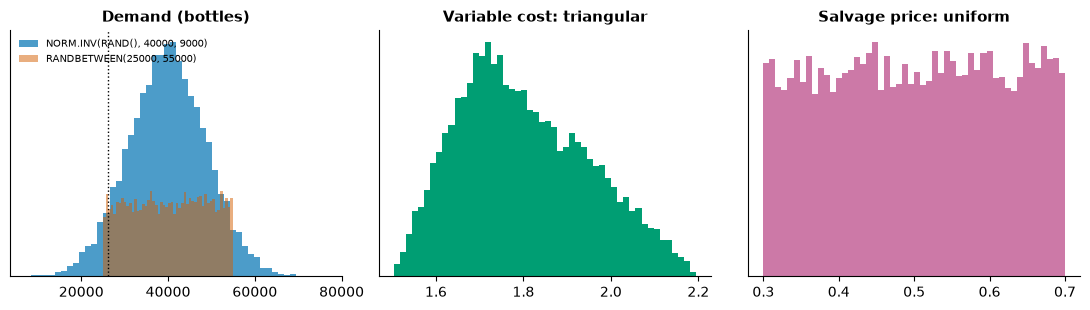

Share below 26,000 bottles, normal:      6.1%
Share below 26,000 bottles, RANDBETWEEN: 3.1%
Mean cost, triangular: $1.801  (most likely $1.70; formula (a+m+b)/3 = $1.800)


In [12]:
rng = np.random.default_rng(7)
n = 10_000
d_normal = rng.normal(40000, 9000, n)
d_between = rng.integers(25000, 55001, n)          # RANDBETWEEN(25000, 55000)
c_tri = rng.triangular(1.50, 1.70, 2.20, n)
s_uni = rng.uniform(0.30, 0.70, n)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
axes[0].hist(d_normal, bins=50, color=BLUE, alpha=0.7, label="NORM.INV(RAND(), 40000, 9000)")
axes[0].hist(d_between, bins=50, color=ORANGE, alpha=0.5, label="RANDBETWEEN(25000, 55000)")
axes[0].axvline(26087, color="black", ls=":", lw=1)
axes[0].set_title("Demand (bottles)")
axes[0].legend(frameon=False, fontsize=7, loc="upper left")
axes[1].hist(c_tri, bins=50, color=GREEN)
axes[1].set_title("Variable cost: triangular")
axes[2].hist(s_uni, bins=50, color=PURPLE)
axes[2].set_title("Salvage price: uniform")
for ax in axes:
    ax.set_yticks([])
plt.tight_layout()
plt.show()

print(f"Share below 26,000 bottles, normal:      {np.mean(d_normal < 26000):.1%}")
print(f"Share below 26,000 bottles, RANDBETWEEN: {np.mean(d_between < 26000):.1%}")
print(f"Mean cost, triangular: ${c_tri.mean():.3f}  (most likely $1.70; formula (a+m+b)/3 = $1.800)")

The two demand distributions have the same average, but the normal one has **tails**: it puts about twice as many seasons below break-even, including some far below 25,000, which `RANDBETWEEN(25000, 55000)` rules out completely. The choice of distribution is an **assumption**, and it changes the answer to "how likely is a loss?". Write it down and justify it, as in the table above.

### Excel steps: the simulation sheet

Add a sheet named `Sim`. Formulas on this sheet may refer to `Model` (only Data Table input cells must share the table's sheet). First add the distribution settings to `Model` as blue inputs:

1. On `Model`: `A16` *Demand mean*, `B16` `40000`; `A17` *Demand SD*, `B17` `9000`; `A18` *Cost minimum*, `B18` `1.5`; `A19` *Cost most likely*, `B19` `1.7`; `A20` *Cost maximum*, `B20` `2.2`; `A21` *Salvage low*, `B21` `0.3`; `A22` *Salvage high*, `B22` `0.7`.
2. On `Sim`, row 1 headers: `A1` *Trial*, `B1` *U for cost*, `C1` *Demand*, `D1` *Unit cost*, `E1` *Salvage price*, `F1` *Bottles sold*, `G1` *Profit*.
3. `A2` `1`; `A3` `=A2+1`.
4. `B2` `=RAND()`
5. `C2` `=MAX(0, ROUND(NORM.INV(RAND(), Model!$B$16, Model!$B$17), 0))`
6. `D2` `=IF(B2<(Model!$B$19-Model!$B$18)/(Model!$B$20-Model!$B$18), Model!$B$18+SQRT(B2*(Model!$B$20-Model!$B$18)*(Model!$B$19-Model!$B$18)), Model!$B$20-SQRT((1-B2)*(Model!$B$20-Model!$B$18)*(Model!$B$20-Model!$B$19)))`
7. `E2` `=Model!$B$21+(Model!$B$22-Model!$B$21)*RAND()`
8. `F2` `=MIN(C2, Model!$B$10)`
9. `G2` `=Model!$B$4*F2 + E2*(Model!$B$10-F2) - D2*Model!$B$10 - Model!$E$5`
10. Copy `A3` down to `A1001`. Select `B2:G2`, copy, select `B3:G1001`, paste. You now have **1,000 trials**. (Tip: type `B2:G1001` in the Name Box and press **Ctrl+D** to fill down in one step.)
11. The `$` signs matter: `Model!$B$16` stays fixed when copied down, while `B2` moves to `B3`, `B4`, … Leave them out and row 3 reads the wrong inputs.
12. Press **F9** a few times. Every number changes: each press is a fresh set of 1,000 seasons.

The numpy mirror draws the same inputs for 1,000 trials and builds the same table.

In [13]:
rng = np.random.default_rng(2026)
n_trials = 1_000
u = rng.uniform(0, 1, n_trials)                                    # column B: RAND()
demand = np.maximum(0, np.round(norm.ppf(rng.uniform(0, 1, n_trials), 40000, 9000)))   # NORM.INV(RAND(), ...)
a, m, b = 1.50, 1.70, 2.20
unit_cost = np.where(u < (m - a) / (b - a),                         # the triangular formula, as in Excel
                     a + np.sqrt(u * (b - a) * (m - a)),
                     b - np.sqrt((1 - u) * (b - a) * (b - m)))
salvage = 0.30 + (0.70 - 0.30) * rng.uniform(0, 1, n_trials)        # low + (high - low) * RAND()
sold = np.minimum(demand, Q)
profit = PRICE * sold + salvage * (Q - sold) - unit_cost * Q - FIXED

sim = pd.DataFrame({"trial": np.arange(1, n_trials + 1), "u_cost": u, "demand": demand,
                    "unit_cost": unit_cost, "salvage": salvage, "sold": sold, "profit": profit})
print(sim.head().round(3).to_string(index=False))
print(f"\nAverage profit over {n_trials:,} trials: {usd(profit.mean())}")
print(f"Share of trials with a loss: {np.mean(profit < 0):.1%}")

 trial  u_cost  demand  unit_cost  salvage    sold     profit
     1   0.179 47688.0      1.658    0.559 45000.0  45377.639
     2   0.640 28283.0      1.845    0.693 28283.0 -18309.121
     3   0.467 44778.0      1.768    0.378 44778.0  39627.061
     4   0.371 41739.0      1.731    0.686 41739.0  31315.474
     5   0.355 44962.0      1.725    0.680 44962.0  42256.127

Average profit over 1,000 trials: $14,833
Share of trials with a loss: 27.1%


> **Misconception:** "A random input means the model is guessing." The randomness is **structured**: each input is drawn from a distribution chosen from data (the regression) or from documented judgement (the triangular cost). What is random is **which** season we get, not the rules of the business.

> **Check your understanding.** A colleague models a count of rainy festival days with `=RANDBETWEEN(0, 5)` in Excel and mirrors it in numpy as `rng.integers(0, 5)`. Why will the two never agree, and what is the fix?

---

## Part 8: Freezing a simulation: Paste Special → Values (core)

`RAND()`, `RANDBETWEEN()` and anything built on them are **volatile**: Excel recalculates them whenever anything in the workbook changes, when you open the file, and when you press F9. That is how the simulation works, but it means the numbers in your report will not match the workbook your manager opens tomorrow.

### Excel steps: freeze the results

1. Decide which results to keep. Usually you keep the full trial table **and** a copy of the summary.
2. Select the simulated block, for example `Sim!A1:G1001`, and copy it (**Ctrl+C** / **Cmd+C**).
3. **Best practice:** paste onto a **new sheet** named `Sim frozen` so that the live model survives: click `A1` there → **Home → Paste ▾ → Paste Values** (the clipboard icon with **123**). Or right-click → **Paste Special… → Values → OK**.
4. If you paste the values over the original cells instead, the formulas are **gone**; you would have to rebuild them to run again. Keep a saved copy first.
5. Write a note beside the frozen table: date, number of trials, and "frozen with Paste Special → Values".

Two alternatives, each with a cost:

- **Formulas → Calculation Options → Manual.** Nothing recalculates until you press F9. But this setting travels with Excel, not just the file, and a colleague may see stale numbers everywhere without knowing why.
- **Data → Data Analysis → Random Number Generation** (Analysis ToolPak) can generate random numbers from several distributions with a **Random Seed** box. Its output is plain numbers, not formulas, so it is reproducible, but it does not refresh.

In Python the **seed** does the freezing: the same seed gives the same numbers on every run, on every computer with the same numpy version.

In [14]:
def run(seed, n=1_000):
    """One simulated batch of Brightleaf seasons; returns the profits."""
    r = np.random.default_rng(seed)
    d = np.maximum(0, np.round(r.normal(40000, 9000, n)))
    c = r.triangular(1.50, 1.70, 2.20, n)
    s = r.uniform(0.30, 0.70, n)
    return brew_profit(d, c, s)


print("Seed 1, run twice: ", usd(run(1).mean()), usd(run(1).mean()))
print("Seeds 2, 3 and 4:  ", usd(run(2).mean()), usd(run(3).mean()), usd(run(4).mean()))

Seed 1, run twice:  $14,841 $14,841
Seeds 2, 3 and 4:   $15,158 $16,708 $15,515


Same seed, same answer; different seeds, slightly different answers. Neither is "the right one". The spread between them is the subject of the next part.

> **Misconception:** "Freezing the numbers makes the result more accurate." It makes it **repeatable**. If 1,000 trials gave a noisy estimate, the frozen copy is the same noisy estimate, now fixed in place.

---

## Part 9: How many trials? (core)

Each simulated batch is a **sample** of possible seasons, so every statistic from it (the average profit, the probability of a loss) has **sampling error**, exactly like a survey. More trials, less error, but with diminishing returns: the error shrinks with the **square root** of the number of trials.

- **Standard error of the average:** SD of the trial results ÷ √n.
- **Standard error of a probability** *p*: √(p × (1 − p) ÷ n).

Quadrupling the trials halves the error. Going from 1,000 to 100,000 trials makes the error ten times smaller.

> **Predict, then run.** The true probability of a loss in this model is about 25%. With only **50** trials, how far from 25% could one batch's estimate easily be: 1 point, 5 points or 15 points?

 trials five batches (probability of loss) ± 2 standard errors
     50  24.0%  32.0%  26.0%  24.0%  18.0%             ± 12.2%
    500  26.6%  27.6%  27.0%  26.4%  25.2%              ± 4.0%
   5000  24.7%  26.4%  25.6%  24.7%  25.7%              ± 1.2%
  50000  24.9%  25.4%  25.0%  25.2%  25.6%              ± 0.4%


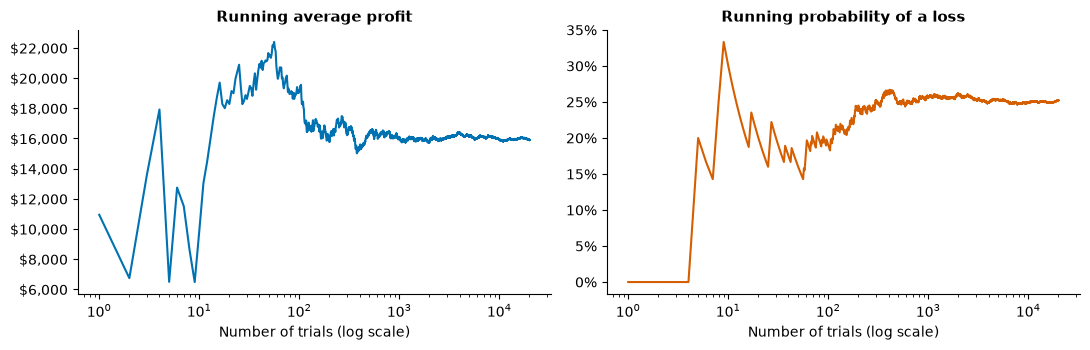

In [15]:
rows = []
for n in (50, 500, 5_000, 50_000):
    estimates = [np.mean(run(seed, n) < 0) for seed in range(100, 105)]
    p = np.mean(estimates)
    rows.append({"trials": n, "five batches (probability of loss)": "  ".join(f"{e:.1%}" for e in estimates),
                 "± 2 standard errors": f"± {2 * np.sqrt(p * (1 - p) / n):.1%}"})
print(pd.DataFrame(rows).to_string(index=False))

long = run(99, 20_000)
k = np.arange(1, len(long) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(k, np.cumsum(long) / k, color=BLUE)
axes[0].set_xscale("log")
axes[0].set_title("Running average profit")
axes[0].yaxis.set_major_formatter(lambda v, _: usd(v))
axes[1].plot(k, np.cumsum(long < 0) / k, color=ORANGE)
axes[1].set_xscale("log")
axes[1].set_title("Running probability of a loss")
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
for ax in axes:
    ax.set_xlabel("Number of trials (log scale)")
plt.tight_layout()
plt.show()

With 50 trials, one batch can report a probability of loss several points away from another, enough to change how risky the launch sounds. The running lines wander early and settle as trials accumulate.

How to choose the number of trials:

1. Decide how precise each number must be for the **decision**. If the board will act differently at a 20% and a 30% chance of loss, the estimate must be good to well under ±5 points.
2. Use the standard-error formulas to find the **n** that gives that precision. For ±2 points at p ≈ 25%: n ≈ 4 × 0.25 × 0.75 ÷ 0.02² ≈ **1,900** trials.
3. Run the batch twice with different seeds (in Excel: press F9 and compare). If the answer that matters moves, add trials.
4. **Tails need more trials than averages.** A 5th percentile is estimated from the worst few percent of trials only, so it is noisier than the mean.
5. Report the estimate **with** its precision: "about 25% (± 2 points)".

In Excel, 1,000 to 10,000 rows are practical. For more, a classic trick is a one-way **Data Table with an empty input cell**: list 1 to 1,000 in a column, put a summary cell (such as the average profit of the `Sim` sheet) in the formula row, choose any **empty** cell on the same sheet as the *Column input cell*, and Excel recalculates the whole sheet once per row, collecting 1,000 batch results (an extension; it is slow on large sheets).

> **Misconception:** "My simulation gives a 24.1% chance of loss." The **decimal** is noise unless you ran tens of thousands of trials. Round to what the trials support.

---

## Part 10: Risk measures and reading the histogram (core)

An average alone is a poor summary of risk. These measures describe the **whole distribution** of outcomes:

| Measure | Question it answers | Excel (results in `Sim!G2:G1001`) | numpy |
|---|---|---|---|
| Mean | What do we earn on average? | `=AVERAGE(G2:G1001)` | `profit.mean()` |
| Standard deviation | How spread out are the outcomes? | `=STDEV.S(G2:G1001)` | `profit.std(ddof=1)` |
| Probability of loss | How often do we lose money? | `=COUNTIF(G2:G1001,"<0")/COUNT(G2:G1001)` | `np.mean(profit < 0)` |
| 5th percentile (P5) | How bad is a 1-in-20 bad season? | `=PERCENTILE.INC(G2:G1001, 0.05)` | `np.percentile(profit, 5)` |
| Median (P50) | What is the middle outcome? | `=MEDIAN(G2:G1001)` | `np.median(profit)` |
| 95th percentile (P95) | How good is a 1-in-20 good season? | `=PERCENTILE.INC(G2:G1001, 0.95)` | `np.percentile(profit, 95)` |
| Minimum and maximum | What did the worst and best trials show? | `=MIN(...)`, `=MAX(...)` | `profit.min()`, `profit.max()` |
| Chance of meeting the plan | How often do we reach the base-case profit? | `=COUNTIF(G2:G1001,">="&26000)/COUNT(G2:G1001)` | `np.mean(profit >= 26000)` |
| Expected shortfall (extension) | When a bad season happens, how bad is it on average? | `=AVERAGEIF(G2:G1001,"<="&P5cell)` | `profit[profit <= p5].mean()` |

Two notes on matching Excel and numpy. `STDEV.S` divides by n − 1, so use `ddof=1`; numpy's default (`ddof=0`) gives a slightly smaller number. numpy's default percentile method gives the same result as `PERCENTILE.INC`.

**P5 as value at risk.** Banks summarise risk with **value at risk (VaR)**: the loss that is exceeded only with a small probability, such as 5%. The 5th percentile of profit plays the same role here. If P5 is −$30,000, then "in one season out of twenty, we lose $30,000 or more". It is not the worst case; one season in twenty is worse.

**Minimum and maximum are weak measures.** They come from a **single** trial each, so they change a lot from batch to batch, and they grow more extreme as you add trials. Report percentiles instead.

> **Predict, then run.** Look back at Part 6: profit is capped when demand exceeds the 45,000 bottles brewed. What will that cap do to the **right-hand side** of the histogram?

Mean                                              $15,771
Standard deviation                                $25,119
Probability of loss                                 25.5%
5th percentile (P5)                              -$31,277
Median                                            $21,837
95th percentile (P95)                             $45,845
Minimum                                         -$107,088
Maximum                                           $52,110
Chance of reaching the base-case $26,000            44.0%
Expected shortfall (average of the worst 5%)     -$45,573


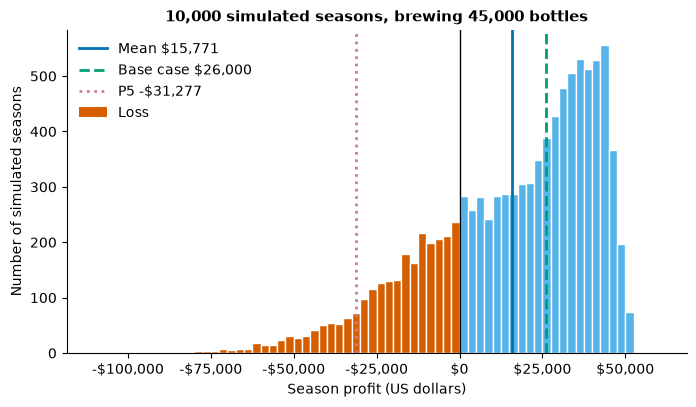

In [16]:
rng = np.random.default_rng(2026)
n = 10_000
demand = np.maximum(0, np.round(rng.normal(40000, 9000, n)))
unit_cost = rng.triangular(1.50, 1.70, 2.20, n)
salvage = rng.uniform(0.30, 0.70, n)
profit = brew_profit(demand, unit_cost, salvage)

p5 = np.percentile(profit, 5)
measures = pd.Series({
    "Mean": usd(profit.mean()),
    "Standard deviation": usd(profit.std(ddof=1)),
    "Probability of loss": f"{np.mean(profit < 0):.1%}",
    "5th percentile (P5)": usd(p5),
    "Median": usd(np.median(profit)),
    "95th percentile (P95)": usd(np.percentile(profit, 95)),
    "Minimum": usd(profit.min()),
    "Maximum": usd(profit.max()),
    "Chance of reaching the base-case $26,000": f"{np.mean(profit >= 26000):.1%}",
    "Expected shortfall (average of the worst 5%)": usd(profit[profit <= p5].mean()),
})
print(measures.to_string())

fig, ax = plt.subplots()
edges = np.arange(-110000, 60001, 2500)               # bin edges that include 0
counts, _ = np.histogram(profit, bins=edges)
ax.bar(edges[:-1], counts, width=2500, align="edge", edgecolor="white",
       color=[ORANGE if e < 0 else SKY for e in edges[:-1]])
ax.bar([0], [0], color=ORANGE, label="Loss")
ax.axvline(0, color="black", lw=1)
ax.axvline(profit.mean(), color=BLUE, lw=2, label=f"Mean {usd(profit.mean())}")
ax.axvline(26000, color=GREEN, ls="--", lw=2, label="Base case $26,000")
ax.axvline(p5, color=PURPLE, ls=":", lw=2, label=f"P5 {usd(p5)}")
ax.set_xlabel("Season profit (US dollars)")
ax.set_ylabel("Number of simulated seasons")
ax.set_title("10,000 simulated seasons, brewing 45,000 bottles")
ax.xaxis.set_major_formatter(lambda v, _: usd(v))
ax.legend(frameon=False, loc="upper left")
plt.show()

### How to read a histogram of outcomes

1. **Find zero.** Everything to its left is a loss. Here roughly a quarter of seasons lose money: a fact the base case of $26,000 completely hides.
2. **Compare the mean with the base case.** The mean sits well left of the base case (Part 6).
3. **Look at the shape.** This one has a **long left tail** (bad seasons can be very bad) and a **pile-up on the right**: once demand exceeds 45,000, every bottle is sold and profit can rise no further, so many seasons bunch just below the ceiling. Their remaining spread comes only from the variable cost. A sharp edge or a pile-up in a histogram usually means a **limit** in the model.
4. **Read the tails with percentiles,** not with the minimum and maximum.
5. **Ask what is missing.** The histogram shows only the uncertainties we built in (Part 14).

### Excel steps: a histogram and the summary box

1. On `Sim`, build the summary in `I1:J10`: labels in column I, formulas from the table above in column J, for example `J1` `=AVERAGE(G2:G1001)`, `J3` `=COUNTIF(G2:G1001,"<0")/COUNT(G2:G1001)`, `J4` `=PERCENTILE.INC(G2:G1001,0.05)`.
2. Select `G1:G1001` → **Insert → Charts → Insert Statistic Chart → Histogram** (Excel 2016 or later; on a Mac the same icon in **Insert → Charts**).
3. Right-click the horizontal axis → **Format Axis → Bins → Bin width** `5000`. Tick **Underflow bin** and set it to `0` to collect all losses into one bar, if you want the loss share to stand out.
4. Add a title in words, such as "One season in four loses money", not "Histogram of G".
5. Remember the histogram is **live**: it changes with every F9. Build it from the frozen sheet (Part 8) for a report.

Older Excel without the Histogram chart: make a column of bin edges (−100000, −95000, … 60000) in `L2:L34`, select `M2:M35`, type `=FREQUENCY(G2:G1001, L2:L34)` and press **Ctrl+Shift+Enter** (or just Enter in Excel 365), then **Insert → Column Chart** of the counts.

> **Check your understanding.** Two plans have the same mean profit. Plan A has P5 = −$5,000; Plan B has P5 = −$40,000. Which would a small start-up with $30,000 in the bank prefer, and why?

---

## Part 11: Correlated inputs (core concept, extension build)

So far each input was drawn **independently**. Real inputs often move together:

- A heatwave raises demand **and** the cost of ice and cold storage: **positive** correlation between demand and cost. Bad news on one side is partly offset on the other (a natural hedge).
- An economic downturn lowers festival crowds **and** pushes the tea supplier to raise prices to cover its own losses: **negative** correlation between demand and cost. Bad news arrives together.

Ignoring a correlation does not change the **average** much, but it can badly misstate the **risk**, because risk lives in the combinations.

> **Predict, then run.** With a correlation of −0.6 between demand and cost, will the probability of a loss be higher or lower than with independent inputs? What about the mean?

 correlation mean profit      SD probability of loss       P5
        -0.6     $15,911 $28,139               27.2% -$37,900
         0.0     $15,893 $24,727               24.9% -$31,216
         0.6     $15,879 $21,001               21.9% -$24,627


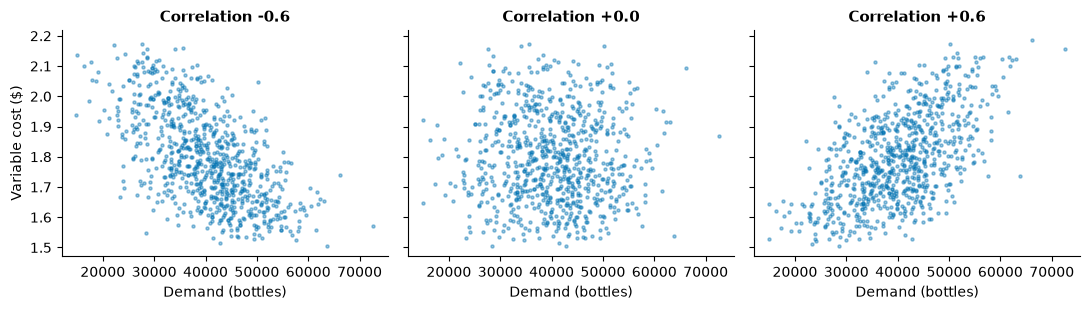

In [17]:
def run_correlated(rho, seed=11, n=20_000):
    """Demand and unit cost linked through correlated standard normal draws (a Gaussian copula)."""
    r = np.random.default_rng(seed)
    z1 = r.standard_normal(n)
    z2 = rho * z1 + np.sqrt(1 - rho ** 2) * r.standard_normal(n)
    d = np.maximum(0, np.round(40000 + 9000 * z1))
    uu = norm.cdf(z2)                                   # a uniform number linked to demand
    c = np.where(uu < (m - a) / (b - a), a + np.sqrt(uu * (b - a) * (m - a)),
                 b - np.sqrt((1 - uu) * (b - a) * (b - m)))
    s = r.uniform(0.30, 0.70, n)
    return d, c, brew_profit(d, c, s)


rows, samples = [], {}
for rho in (-0.6, 0.0, 0.6):
    d, c, p = run_correlated(rho)
    samples[rho] = (d, c)
    rows.append({"correlation": rho, "mean profit": usd(p.mean()), "SD": usd(p.std(ddof=1)),
                 "probability of loss": f"{np.mean(p < 0):.1%}", "P5": usd(np.percentile(p, 5))})
print(pd.DataFrame(rows).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, rho in zip(axes, (-0.6, 0.0, 0.6)):
    d, c = samples[rho]
    ax.scatter(d[:800], c[:800], s=5, alpha=0.4, color=BLUE)
    ax.set_title(f"Correlation {rho:+.1f}")
    ax.set_xlabel("Demand (bottles)")
axes[0].set_ylabel("Variable cost ($)")
plt.tight_layout()
plt.show()

The mean barely moves, but the probability of loss and the 5th percentile do. With negative correlation, low demand tends to come with high cost, so the bad tail gets worse; with positive correlation the two partly cancel. A model that draws every input independently can therefore look **safer** than the business really is.

**In Excel (extension).** Draw two standard normal numbers, then mix them:

1. `H2` `=NORM.S.INV(RAND())` and `I2` `=NORM.S.INV(RAND())`.
2. `J2` `=rho*H2 + SQRT(1-rho^2)*I2`, with `rho` in a named input cell on `Model`.
3. Demand: `=MAX(0, ROUND(Model!$B$16 + Model!$B$17*H2, 0))`.
4. The uniform number for the triangular cost: `=NORM.S.DIST(J2, TRUE)`, used in place of column B.

Where does the correlation come from? From history (the correlation between past demand and past costs), or from judgement, stated and tested with a sensitivity check, exactly as in the table above.

> **Misconception:** "If I don't model a correlation, I am assuming nothing." Drawing inputs independently **is** an assumption: that the correlation is zero.

---

## Part 12: Decision rules: how much to brew (core)

A simulation describes risk. A **decision rule** turns that description into a choice. Brightleaf controls one big lever: **how many bottles to brew**. Brew too few and it runs out in good seasons; brew too many and it pays for bottles it sells off cheaply.

To compare options fairly, every option must face **the same simulated seasons**. This is called **common random numbers**: draw demand, cost and salvage once, then compute each option's profit on those same draws. Otherwise the differences between options are partly just luck.

> **Predict, then run.** Which brew quantity has the highest **average** profit: 35,000, 40,000, 45,000 or 50,000? Will the quantity with the **lowest chance of a loss** be the same one?

brewed    mean probability of loss       P5     P95 chance of running out
30,000  $3,850               19.3% -$11,548 $12,265                   87%
35,000 $11,227               13.9% -$18,027 $23,964                   71%
40,000 $15,303               19.2% -$24,744 $35,215                   50%
45,000 $15,632               25.6% -$31,502 $45,630                   29%
50,000 $12,716               32.4% -$38,356 $54,374                   13%
55,000  $7,717               40.0% -$45,382 $58,383                    5%
60,000  $1,691               47.6% -$52,224 $55,706                    1%


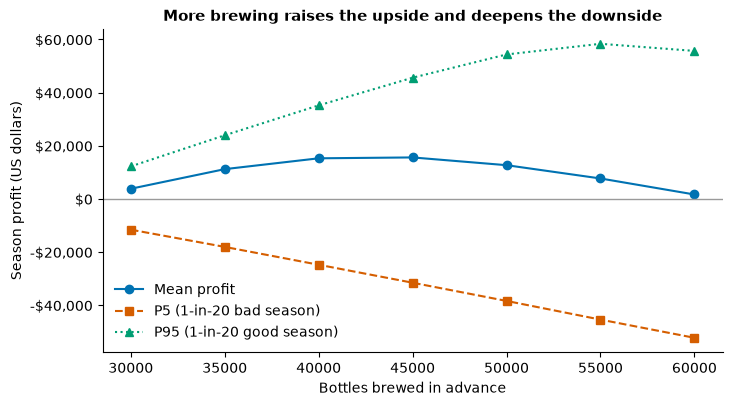

In [18]:
rng = np.random.default_rng(31)
n = 20_000
d = np.maximum(0, np.round(rng.normal(40000, 9000, n)))
c = rng.triangular(1.50, 1.70, 2.20, n)
s = rng.uniform(0.30, 0.70, n)

rows = []
for brewed in range(30000, 60001, 5000):
    p = brew_profit(d, c, s, brewed=brewed)              # the same seasons for every option
    rows.append({"brewed": brewed, "mean": p.mean(), "probability of loss": np.mean(p < 0),
                 "P5": np.percentile(p, 5), "P95": np.percentile(p, 95),
                 "chance of running out": np.mean(d > brewed)})
options = pd.DataFrame(rows)
print(options.to_string(index=False, formatters={
    "brewed": "{:,}".format, "mean": usd, "P5": usd, "P95": usd,
    "probability of loss": "{:.1%}".format, "chance of running out": "{:.0%}".format}))

fig, ax = plt.subplots()
ax.plot(options["brewed"], options["mean"], "o-", color=BLUE, label="Mean profit")
ax.plot(options["brewed"], options["P5"], "s--", color=ORANGE, label="P5 (1-in-20 bad season)")
ax.plot(options["brewed"], options["P95"], "^:", color=GREEN, label="P95 (1-in-20 good season)")
ax.axhline(0, color=GREY, lw=1)
ax.set_xlabel("Bottles brewed in advance")
ax.set_ylabel("Season profit (US dollars)")
ax.set_title("More brewing raises the upside and deepens the downside")
ax.yaxis.set_major_formatter(lambda v, _: usd(v))
ax.legend(frameon=False)
plt.show()

Different rules pick different answers:

| Rule | What it says | Brightleaf's choice (from the table) | Suits |
|---|---|---|---|
| **Maximise the mean** (expected value) | Pick the option with the highest average | Around 40,000–45,000; the two are close | A firm that can absorb bad seasons, with many similar bets |
| **Cap the probability of loss** | Highest mean among options with, say, at most a 15% chance of loss | Around 35,000 | A firm that must not have a losing year (a loan covenant, investors) |
| **Protect the bad case** (maximise P5) | Pick the option with the least bad 1-in-20 season | The smallest brew | A cash-poor start-up that cannot survive a big loss |
| **Maximin** (best worst case) | Judge each option by its worst outcome only | The smallest brew | Very risk-averse; ignores probabilities, so it is rarely used alone |
| **Satisficing** | First option that meets a target, e.g. 60% chance of profit above $10,000 | Depends on the target | Clear, explainable rules agreed in advance |

No rule is "correct". The rule should be chosen **before** looking at the results, from the firm's situation and its **risk appetite**, and stated in the recommendation. Changing the rule after seeing the table, to justify a favourite option, is the simulation equivalent of moving the goalposts.

Notice also how **flat** the mean is near the top: the mean differs by only a few hundred dollars between 40,000 and 45,000, while P5 differs by several thousand. When options are close on the mean, risk measures should decide.

**Extension: the newsvendor rule.** For this kind of problem there is a classic formula. Brew until the chance of selling the last bottle equals the **critical ratio**: (price − cost) ÷ (price − salvage) = (4.00 − 1.80) ÷ (4.00 − 0.50) ≈ 0.63. So brew the 63rd percentile of demand, about 40,000 + 0.33 × 9,000 ≈ 43,000 bottles, which sits where the mean curve peaks. Under-stocking costs $2.20 of lost margin per bottle; over-stocking costs $1.30 per bottle; the ratio balances the two.

---

## Part 13: Communicating risk to executives (core)

Executives do not want a histogram tutorial. They want to know: **what do you recommend, how sure are you, what could go wrong, and what would change your mind?**

> **Predict, then run.** Before running the cell, write a two-sentence summary of the 45,000-bottle plan for Brightleaf's board in your own words. Then compare it with the generated one.

In [19]:
p45 = options.set_index("brewed").loc[45000]
p35 = options.set_index("brewed").loc[35000]
ratio = round(1 / p45["probability of loss"])
print(f"Brewing 45,000 bottles, we expect a season profit of about {usd(round(p45['mean'], -3))}, "
      f"not the {usd(26000)} of the single-number plan.")
print(f"About 1 season in {ratio} loses money; in a bad season (1 in 20) we lose "
      f"{usd(-round(p45['P5'], -3))} or more.")
print(f"Brewing 35,000 instead lowers the average to about {usd(round(p35['mean'], -3))}, but cuts the chance "
      f"of a loss to about 1 in {round(1 / p35['probability of loss'])} and the 1-in-20 loss to about "
      f"{usd(-round(p35['P5'], -3))}.")
print("Demand is the main driver (Part 3); a pre-order campaign would narrow the range most.")

Brewing 45,000 bottles, we expect a season profit of about $16,000, not the $26,000 of the single-number plan.
About 1 season in 4 loses money; in a bad season (1 in 20) we lose $32,000 or more.
Brewing 35,000 instead lowers the average to about $11,000, but cuts the chance of a loss to about 1 in 7 and the 1-in-20 loss to about $18,000.
Demand is the main driver (Part 3); a pre-order campaign would narrow the range most.


| Say | Avoid |
|---|---|
| "About 1 season in 4 loses money" | "P(profit < 0) = 0.256" |
| "We expect about $16,000; in 9 seasons out of 10 the result lies between a loss of about $30,000 and a profit of about $45,000" | "Profit will be $15,632" |
| "In a bad season, 1 in 20, we lose $30,000 or more" | "VaR(95) = 31,502" without explaining it |
| "The main driver is demand" | A list of every input |
| "This assumes no correlation between demand and cost; if a downturn hits both, the risk is higher" | Silence on assumptions |
| "We recommend 35,000 bottles because the board said a loss above $20,000 is unacceptable" | A recommendation with no rule |

**Frequencies beat percentages.** "1 in 4" and "5 out of 20 seasons" are understood far better than "25%" and "P5", especially by people under time pressure (Gigerenzer's work on natural frequencies).

**One chart, with words on it.** Show the histogram (or the options chart), shade the losses, mark zero and the plan, and give it a headline that states the finding.

**A one-slide structure:**

1. **Recommendation** in one sentence.
2. **Expected outcome and range** in words (mean, a P5–P95 range, the chance of loss as a frequency).
3. **Main driver** (from the tornado chart) and what would reduce the uncertainty.
4. **Key assumptions** (distributions, independence) and **what the model leaves out** (Part 14).
5. **Decision rule** used, and how the choice would change under another rule.

> **Misconception:** "More decimals look more rigorous." They signal false precision. A simulation with uncertain inputs supports two significant figures at most.

---

## Part 14: Business case: Brightleaf's launch decision (core discussion)

The board meets next week. The founders want to brew 45,000 bottles: "the regression says 40,000, plus a safety margin". The finance lead wants 35,000. An investor asks whether to launch at all this year, or to run a ten-festival pilot first.

What the simulation shows and **does not** show:

| Captured in the model | Not captured |
|---|---|
| Demand uncertainty from the regression | Customer disappointment when Brightleaf runs out at a festival, and the effect on next year's brand |
| Cost uncertainty (triangular judgement) | Waste: unsold bottles that the discount retailer cannot take end up discarded, with an environmental cost and possible reputational cost |
| Salvage price range | A food-safety recall, which no input in the model represents |
| The brewing cap | The option to brew a **second batch** mid-season at a higher cost, which would soften the cap |
| | Whether past sister-brand launches are a fair guide to a new product (Part 1, question 5) |

A precise number on a screen can crowd out risks that were never typed into a cell. The model's silence on a risk is not evidence that the risk is small.

**Discussion questions** (pairs, 10 minutes):

1. Which decision rule from Part 12 fits a start-up with $30,000 in the bank? Which fits a large drinks company launching its tenth product?
2. The founders' "safety margin" brews **more**. Explain, using the histogram, why brewing more is not safer in this model. In what business would a safety margin of extra stock really be safer?
3. Suppose a mid-season second batch is possible at $2.10 a bottle, ordered after the first ten festivals. Without coding it, how would it change the shape of the histogram and the best first-batch size?
4. The pilot costs $8,000 and would shrink the demand standard deviation from 9,000 to 4,000 bottles. Which numbers from this lecture would you use to judge whether that information is worth $8,000? (This is the idea of the **value of information**.)
5. Write the recommendation in four parts: **finding, evidence, action with an owner, and what would change it**.

---

## Part 15: Lab 5 bridge: train and test, residuals (core)

Lab 5, in periods 7 and 8, returns to **predictive regression** in Python: you fit a multiple regression on car data, test it on cars it has not seen and check its residuals. This part is a 30-minute recap of the Day 4 ideas the lab uses, on a **different** data set: weekly cold-brew orders from 250 cafés that stock Brightleaf (synthetic). The lab asks you to interpret **your own** output; nothing here tells you what that output will show.

| Lab 5 step | What it does | Day 4 recap |
|---|---|---|
| Drop missing values; choose features **X** and target **y** | A regression cannot use a row with a gap | Parts 2–3 |
| Split 80% / 20% with a fixed `random_state` | The test set plays "cars the model has never seen" | Part 5 |
| Fit, read the coefficients | Each coefficient in units of the target, per sensible step, holding the others constant | Parts 2–3 |
| RMSE, MAE, R² on the **test** set | Typical error in the target's units; share of variation explained | Part 6 |
| Actual vs predicted plot with a y = x line | Points on the line are perfect predictions | below |
| Residuals vs predicted | A flat, even band is healthy; a curve or funnel is a warning | Part 7 |

> **Predict, then run.** The cafés' true orders rise with temperature, but **faster** on hot weeks than on mild ones. We fit a straight-line model. What shape will the residual plot show?

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(15)
n = 250
cafes = pd.DataFrame({
    "temperature": rng.uniform(12, 34, n).round(1),       # average weekly temperature, deg C
    "seats": rng.integers(10, 80, n),
    "promo_display": rng.integers(0, 2, n),
})
cafes["bottles"] = (20 + 0.25 * (cafes["temperature"] - 10) ** 2 + 0.9 * cafes["seats"]
                    + 15 * cafes["promo_display"] + rng.normal(0, 6, n)).round()

features = ["temperature", "seats", "promo_display"]
X, y = cafes[features], cafes["bottles"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
lin = LinearRegression().fit(X_train, y_train)
pred_test = lin.predict(X_test)

print(f"Training cafés: {len(X_train)}, test cafés: {len(X_test)}")
print(pd.Series(lin.coef_, index=features).round(2).to_string())
print(f"Test RMSE {np.sqrt(mean_squared_error(y_test, pred_test)):.1f} bottles, "
      f"MAE {mean_absolute_error(y_test, pred_test):.1f} bottles, R² {r2_score(y_test, pred_test):.2f}")

Training cafés: 200, test cafés: 50
temperature       6.89
seats             0.93
promo_display    16.16
Test RMSE 9.7 bottles, MAE 7.9 bottles, R² 0.94


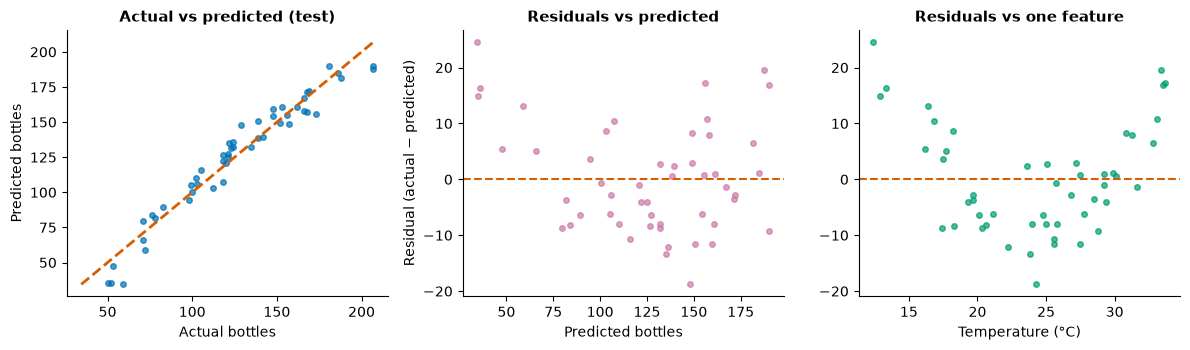

In [21]:
resid = y_test - pred_test
lo_ = min(y_test.min(), pred_test.min())    # the y = x line should span both axes' data
hi_ = max(y_test.max(), pred_test.max())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].scatter(y_test, pred_test, color=BLUE, s=16, alpha=0.7)
axes[0].plot([lo_, hi_], [lo_, hi_], color=ORANGE, ls="--", lw=2)
axes[0].set_xlabel("Actual bottles")
axes[0].set_ylabel("Predicted bottles")
axes[0].set_title("Actual vs predicted (test)")
axes[1].scatter(pred_test, resid, color=PURPLE, s=16, alpha=0.7)
axes[1].axhline(0, color=ORANGE, ls="--")
axes[1].set_xlabel("Predicted bottles")
axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Residuals vs predicted")
axes[2].scatter(X_test["temperature"], resid, color=GREEN, s=16, alpha=0.7)
axes[2].axhline(0, color=ORANGE, ls="--")
axes[2].set_xlabel("Temperature (°C)")
axes[2].set_title("Residuals vs one feature")
plt.tight_layout()
plt.show()

How to read the three plots, step by step (use the same steps on your own Lab 5 output):

1. **Actual vs predicted.** Are the points close to the dashed line everywhere, or further from it at one end? Points **above** the line are over-predictions; points **below** are under-predictions.
2. **Residuals vs predicted.** Imagine a smooth line through the points. Flat at zero? Or does it bend (a **curve**: the model has the wrong shape) or fan out (a **funnel**: errors grow with the prediction)?
3. **Residuals vs one feature.** If the residual plot shows a pattern, plot the residuals against each feature to find **which** one causes it. Here the U-shape against temperature points to the curved temperature effect we built in.
4. **Write it as a finding**, with units: "the model under-predicts on the coldest and the hottest weeks, by up to about … bottles", then say what you would try next (a squared term, a log, another feature).

Three habits that prevent most Lab 5 slips:

- **Draw the y = x line across the data actually plotted.** A line from the smallest to the largest value of the **target** works only if the predictions stay inside that range and `y` still holds the target (see the Lab 5 guide's pitfalls).
- **Test-set numbers are the honest ones.** Quote RMSE, MAE and R² from the test set and say so.
- **Name the step size and units** in every coefficient sentence: per degree, per 10 seats, per 1,000 of something; choose a step that makes sense for the feature's range.

The [Lab 5 guide](guides/lab5_regression.md) has the offline route, checks you can make without seeing answers, and the known pitfalls.

---

## Part 16: Practice, quiz and summary

### Practice

#### Core

**Core 1.** In the simple model (Part 2), the festivals offer a deal: stall fee $900 a day, but Brightleaf must book 36 days. Assume demand rises by 1,400 bottles per extra day (Part 1). Compute the new fixed costs, break-even and profit. Is the deal worth it?

**Core 2.** Build a one-way Data Table (Excel) and its numpy mirror for **variable cost** from $1.40 to $2.40 in steps of $0.10, showing profit and break-even demand. At what cost does the base case stop being profitable?

**Core 3.** Re-run the Part 10 simulation with 2,000 trials and three different seeds. Report the mean profit and the probability of loss for each, and the ± 2 standard error range for the probability.

**Core 4.** Write three sentences for the board about the 40,000-bottle option in Part 12, following the "Say" column in Part 13.

#### Stretch

**Stretch 1.** Replace the normal demand with a triangular distribution (25,000, 40,000, 55,000). Compare the probability of loss and P5 with the normal version. Which assumption would you defend to an investor, and why?

**Stretch 2.** Use Goal Seek (Excel) or `goal_seek` (numpy) on the brew-in-advance model at base inputs: what salvage price makes brewing 50,000 bottles give the same base-case profit as brewing 45,000? Why is the answer unrealistic?

**Stretch 3.** Draw a tornado chart for the **brew-in-advance** model (Part 6), using the same input ranges plus bottles brewed (35,000 to 55,000). How does the ranking change, and why does demand's bar become lopsided?

#### Challenge

**Challenge 1.** Code the mid-season second batch from Part 14, question 3: after the first third of the season, if demand is on track to exceed the first batch, Brightleaf brews up to 10,000 more at $2.10 a bottle. Rerun Part 12's options table with this option and describe how the histogram and the best first batch change.

**Challenge 2.** Value of information: compare the decision and the expected profit with demand SD 9,000 and SD 4,000 (Part 14, question 4), choosing the best brew quantity under each. Is the pilot worth $8,000 under the "maximise the mean" rule? Under the "protect P5" rule?

**Challenge 3.** Build the Excel "Data Table with an empty input cell" trick (Part 9) for 200 recalculations of the average profit of a 500-trial sheet. Compare the spread of those 200 averages with the standard-error formula.

### Quiz

1. What is the difference between an input, a calculation and an output in a spreadsheet model? Why are inputs coloured differently?
2. Fixed costs are $60,000 and the contribution margin is $2.30. What is the break-even demand, and what happens to it if the price rises by $0.20?
3. What does the widest bar on a tornado chart tell a manager to do?
4. You build a Data Table on a new sheet and Excel says *"Input cell reference is not valid"*. Why, and what is the fix?
5. In a two-way Data Table, where does the output formula go, and which input cell box gets the values that run along the top row?
6. What does Goal Seek do to the input cell, and why does that matter?
7. Explain the flaw of averages with an example from a business you know.
8. Write the Excel formula for a normally distributed demand with mean 5,000 and standard deviation 800, never below zero.
9. Why must the uniform number for a triangular draw be in its own cell?
10. A simulation with 100 trials gives a 12% chance of loss. Roughly how precise is that estimate?
11. Explain "P5 = −$30,000" to a manager without using the word percentile.
12. Why can ignoring a negative correlation between demand and cost make a plan look safer than it is?
13. Name two decision rules and a business situation that suits each.
14. Give one risk that a spreadsheet simulation of a product launch would not capture, and say how you would mention it in a report.

### Summary

| Idea | Remember |
|---|---|
| Regression to model input | Use the prediction **and** its standard error: `NORM.INV(RAND(), prediction, SE)` |
| Model structure | Inputs (blue), calculations (black), outputs (boxed); never type numbers into formulas |
| Contribution margin and break-even | Margin = price − variable cost; break-even = fixed costs ÷ margin |
| Tornado chart | One input at a time; widest bar = biggest driver; misses combinations |
| Data Table | Sweep one or two inputs; **input cells on the table's sheet**; a sweep, not a simulation |
| Scenarios and Goal Seek | Coherent stories, not probabilities; Goal Seek solves backwards and overwrites the input |
| Flaw of averages | Average inputs give the average output only in straight-line models; kinks and skew break it |
| Monte Carlo | Random draws from chosen distributions, thousands of trials; `RAND`, `RANDBETWEEN`, `NORM.INV`, triangular by formula |
| Freezing | Paste Special → Values on a copy; in Python, a fixed seed |
| Trials | Error shrinks with √n; report estimates with their precision; tails need more trials |
| Risk measures | Mean **and** probability of loss, P5, P95; minimum and maximum are unstable |
| Correlation | Independent draws assume zero correlation; risk lives in the combinations |
| Decision rules | Choose the rule before the results; when means are close, let risk decide |
| Communication | Recommendation first; frequencies ("1 in 4"); one labelled chart; assumptions and omissions stated |

**References:** Gordon, M. E. (2023). *Business analytics: Combining data, analysis and judgement to inform decisions* (Chapter 9, "Financial Analytics"). SAGE. Savage, S. L. (2009). *The flaw of averages: Why we underestimate risk in the face of uncertainty*. Wiley. Winston, W. L. (2021). *Microsoft Excel data analysis and business modeling* (7th ed.). Microsoft Press. Gigerenzer, G. (2002). *Calculated risks: How to know when numbers deceive you*. Simon & Schuster. Wall Street Prep (n.d.). *Financial modeling guide*. Workday (n.d.). *Financial forecasting in Excel made easy*.

**Next:** Lab 5 in periods 7 and 8, with the [Lab 5 guide](guides/lab5_regression.md). Tomorrow, Lab 6 applies Parts 2–10 to a new business in Excel.

---

## For the facilitator

This notebook covers **periods P1–P6** of Day 5; Lab 5 runs in P7–P8. No graded answers are given: the case (Brightleaf) and every number in it are invented for this lecture and differ from Lab 6, Lab 7 and Assignment 3; Part 15 uses synthetic café data, never the car data of Lab 5, and draws no conclusion about Lab 5's output.

Have Excel open beside the notebook and build the `Model` and `Sim` sheets live as you go; students build along. Each Excel result has a numpy check printed in the notebook.

| Period | Minutes | Content | Notes |
|---|---|---|---|
| P1 | 10 | Setup; Part 1 case and the regression output | Collect slope guesses first |
| P1 | 20 | Part 1: the manager's reading table; the prediction interval chart | Ask: "Which number would you put on the planning slide?" |
| P1 | 15 | Part 1 Excel steps (`FORECAST.LINEAR`, `STEYX`); five questions | ToolPak step is optional if installs are locked |
| P2 | 25 | Part 2: layers, base case, margin, break-even; build `Model` live | Students predict the profit and margin of safety on paper |
| P2 | 20 | Part 3: tornado ranges, chart; Excel steps 1–4 (the chart itself can be homework) | Ask for the ranking before running |
| P3 | 25 | Part 4: one- and two-way Data Tables in Excel; the error table | Let one student trigger *Input cell reference is not valid* on purpose |
| P3 | 20 | Part 5: Scenario Manager, Goal Seek (Cancel vs OK) | Report the break-even in words, not decimals |
| P4 | 12 | Part 6: the pencil example on the board, then the three-way comparison | Votes on the order before running |
| P4 | 20 | Part 7: distributions; build `Sim` live with 1,000 rows | Watch for missing `$` signs and a second `RAND()` in the triangular formula |
| P4 | 5 | Part 8: Paste Special → Values on a copy | |
| P4 | 8 | Part 9: trials table, running lines | Students press F9 and call out their probability of loss |
| P5 | 15 | Part 10: measures table; read the histogram aloud (the five steps) | Ask what causes the pile-up on the right |
| P5 | 10 | Part 11: correlation table (concept only) | Excel build is an extension |
| P5 | 12 | Part 12: options table; the rules table | Ask which rule they would choose **before** showing the table |
| P5 | 8 | Part 13: generated summary; Say / Avoid table | Pairs rewrite one sentence |
| P6 | 12 | Part 14: questions 1, 2 and 5 | Set 3 and 4 as Challenge work |
| P6 | 30 | Part 15: Lab 5 bridge; open the Lab 5 guide | Make sure Route B students have `data/mpg.csv` before P7 |
| P6 | 3 | Lab 5 logistics: file name, PDF export, deadline | |
| Self-study | — | Part 16: practice and quiz | Core 2 and Stretch 1 are good preparation for Lab 6 |

If P2 overruns, leave the tornado chart's Excel formatting (steps 5–8) for homework. If P4 is short, demonstrate the `Sim` sheet with 100 rows and skip the "empty input cell" trick. If students struggle with distributions, teach only normal and uniform in Part 7 and present the triangular formula as a copy-and-use recipe. Part 11's Excel build and Part 12's newsvendor note are extensions.